# 05.6 · Hyperparameter tuning: grid, random, Bayesian

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/06-hyperparameter-tuning/lesson.ipynb)

Read the [README](README.md) first and count the fits by hand. This notebook:

1. Scores an untuned LightGBM against the logistic-regression baseline from Module 03.
2. Draws why random search beats a grid when only some settings matter.
3. Tunes with `GridSearchCV`, `RandomizedSearchCV` and Optuna, all using cross-validation on the **training** customers only.
4. Opens the test set exactly once, at the end, to see what tuning actually bought.

## 1. The churn table and the baseline to beat

In [1]:
import os, logging
os.environ["PYTHONWARNINGS"] = "ignore"
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)

# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
auc_logreg = roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1])
print(f"Logistic regression baseline, test AUC: {auc_logreg:.3f}")

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # the same 5 folds for every setting

3,317 customers, churn rate 43.6%, train 2,487 / test 830
Logistic regression baseline, test AUC: 0.741


Now LightGBM with its out-of-the-box settings. `n_jobs=1` keeps each model on one CPU core; the search tools run several models in parallel instead, which is much faster than both fighting for cores.

In [2]:
default_lgb = lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=42, n_jobs=1)
scores = cross_val_score(default_lgb, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV AUC per fold:", scores.round(3))
print(f"mean {scores.mean():.3f}  ±  std {scores.std():.3f}")

CV AUC per fold: [0.681 0.738 0.658 0.687 0.726]
mean 0.698  ±  std 0.030


The "powerful" model, untuned, is *worse* than plain logistic regression (0.741). Its defaults (31 leaves per tree, learning rate 0.1) are built for datasets with hundreds of thousands of rows. On 2,487 customers they overfit. This is exactly the situation tuning is for.

Note the **std**: fold scores wander by about ±0.03. Keep that number in mind; any "improvement" smaller than that may be luck.

## 2. Why random search beats a grid (the picture)

Pretend the CV score depends only on the learning rate, and `num_leaves` does nothing. Both searches get 9 tries.

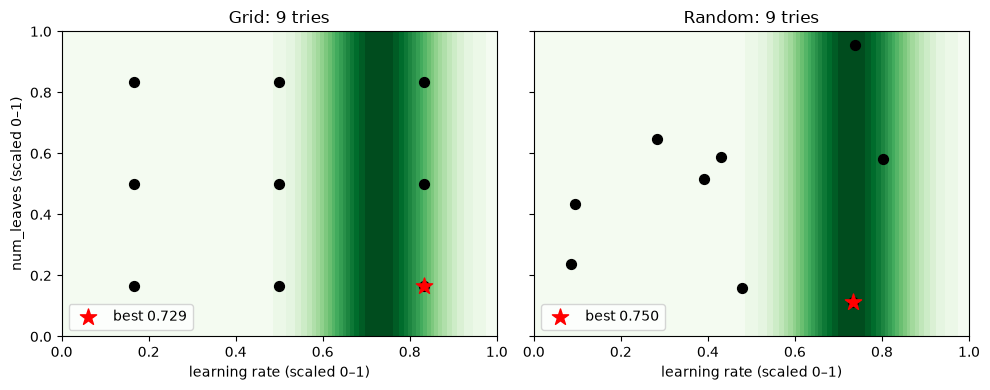

In [3]:
def toy_score(lr, leaves):
    """A pretend CV score: only the learning rate matters, leaves does nothing."""
    return 0.70 + 0.05 * np.exp(-((lr - 0.73) ** 2) / 0.02) + 0 * leaves

grid_pts = [(a, b) for a in [1/6, 3/6, 5/6] for b in [1/6, 3/6, 5/6]]
rng = np.random.default_rng(3)
rand_pts = [tuple(p) for p in rng.uniform(0, 1, size=(9, 2))]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
xs = np.linspace(0, 1, 200)
for ax, pts, title in [(axes[0], grid_pts, "Grid: 9 tries"), (axes[1], rand_pts, "Random: 9 tries")]:
    LR, LV = np.meshgrid(xs, xs)
    ax.contourf(LR, LV, toy_score(LR, LV), levels=20, cmap="Greens")
    ax.scatter(*zip(*pts), color="black", s=50)
    best = max(pts, key=lambda p: toy_score(*p))
    ax.scatter(*best, color="red", s=150, marker="*", label=f"best {toy_score(*best):.3f}")
    ax.set_title(title); ax.set_xlabel("learning rate (scaled 0–1)"); ax.legend(loc="lower left")
axes[0].set_ylabel("num_leaves (scaled 0–1)")
plt.tight_layout(); plt.show()

In [4]:
for name, pts in [("grid", grid_pts), ("random", rand_pts)]:
    distinct = sorted({round(p[0], 3) for p in pts})
    best = max(toy_score(*p) for p in pts)
    print(f"{name:<6}: {len(distinct)} different learning rates tried, best score {best:.3f}")
print(f"true best possible:        {toy_score(0.73, 0):.3f}")

grid  : 3 different learning rates tried, best score 0.729
random: 9 different learning rates tried, best score 0.750
true best possible:        0.750


The grid spends its 9 tries on only **3** learning rates, repeating each with three leaf values that make no difference. Random search tries **9** different learning rates and lands much closer to the peak. In real problems a few hyperparameters matter and most do not, and you rarely know in advance which. That is why random search is the sensible default.

## 3. Grid search on the real model

Two hyperparameters, three values each, five folds: **3 × 3 × 5 = 45 fits**, plus one final refit on all training data.

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {"learning_rate": [0.01, 0.03, 0.1], "num_leaves": [4, 8, 31]}
grid = GridSearchCV(default_lgb, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)                     # test set not touched

print("best settings:", grid.best_params_)
print(f"best CV AUC:   {grid.best_score_:.3f}")

best settings: {'learning_rate': 0.01, 'num_leaves': 4}
best CV AUC:   0.744


In [6]:
res = pd.DataFrame(grid.cv_results_)
table = res.pivot(index="param_num_leaves", columns="param_learning_rate", values="mean_test_score")
table.round(3)

param_learning_rate,0.01,0.03,0.10
param_num_leaves,,,
4,0.744,0.741,0.729
8,0.743,0.735,0.722
31,0.727,0.714,0.698


Read the table: small trees (`num_leaves` 4) and slow learning (0.01) do best, and the default corner (31 leaves, 0.1) is worst. Every cell is a 5-fold CV average on training customers.

## 4. Random search: more settings, same budget

`RandomizedSearchCV` draws each setting from a *distribution* you give it. `loguniform(0.005, 0.3)` spreads tries evenly across orders of magnitude (0.005–0.05 gets as many as 0.05–0.3), which suits learning rates.

In [7]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

param_dist = {"learning_rate": loguniform(0.005, 0.3),
              "num_leaves": randint(2, 64),
              "min_child_samples": randint(5, 100)}
rand = RandomizedSearchCV(default_lgb, param_dist, n_iter=20, cv=cv, scoring="roc_auc",
                          random_state=42, n_jobs=-1).fit(X_train, y_train)
print("best settings:", {k: round(v, 4) if isinstance(v, float) else v for k, v in rand.best_params_.items()})
print(f"best CV AUC:   {rand.best_score_:.3f}")

best settings: {'learning_rate': np.float64(0.006), 'min_child_samples': 55, 'num_leaves': 8}
best CV AUC:   0.742


## 5. Bayesian search with Optuna

Grid and random search do not learn from earlier tries. **Optuna** does: after each trial it updates a model of "which regions score well" and proposes the next setting where improvement looks most likely. You write one function that builds a model from a `trial` and returns its CV score.

In [8]:
import optuna

def objective(trial):
    model = lgb.LGBMClassifier(
        n_estimators=200, verbose=-1, random_state=42, n_jobs=1,
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        num_leaves=trial.suggest_int("num_leaves", 2, 64),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 100))
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)
print("best settings:", {k: round(v, 4) if isinstance(v, float) else v for k, v in study.best_params.items()})
print(f"best CV AUC:   {study.best_value:.3f}")

best settings: {'learning_rate': 0.0146, 'num_leaves': 7, 'min_child_samples': 30}
best CV AUC:   0.745


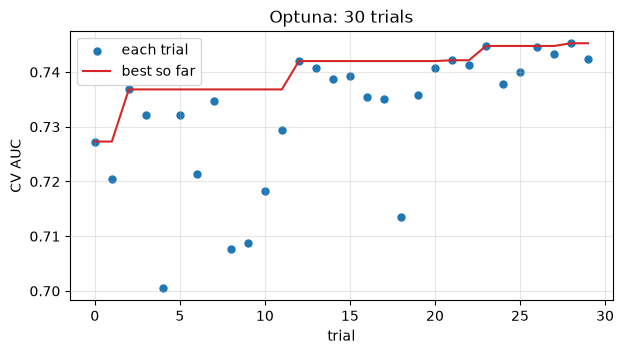

In [9]:
vals = study.trials_dataframe()["value"]
plt.figure(figsize=(7, 3.5))
plt.scatter(vals.index, vals, s=25, label="each trial")
plt.plot(vals.cummax(), color="tab:red", label="best so far")
plt.xlabel("trial"); plt.ylabel("CV AUC"); plt.title("Optuna: 30 trials")
plt.legend(); plt.grid(alpha=.3); plt.show()

Typical pattern: the best-so-far line jumps early and then flattens. Most of the gain comes in the first 10–20 trials.

## 6. Open the test set, once

Every decision so far used only training customers. Now score each finalist on the 830 test customers, one time.

In [10]:
best_optuna = lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=42, n_jobs=1,
                                 **study.best_params).fit(X_train, y_train)
default_fit = default_lgb.fit(X_train, y_train)
finalists = {"logistic regression (Module 03)": logreg, "LightGBM, default": default_fit,
             "LightGBM, grid": grid.best_estimator_, "LightGBM, random": rand.best_estimator_,
             "LightGBM, Optuna": best_optuna}
summary = pd.DataFrame({name: {"test AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
                        for name, m in finalists.items()}).T
summary.round(3)

,test AUC
logistic regression (Module 03),0.741
"LightGBM, default",0.693
"LightGBM, grid",0.739
"LightGBM, random",0.734
"LightGBM, Optuna",0.740


## 7. How much did tuning buy?

Two honest conclusions:

1. **Tuning mattered for LightGBM.** Its defaults scored clearly below the baseline; tuned versions climb by about 0.04–0.05 AUC, which is more than the fold-to-fold noise. Badly chosen defaults are the most common reason a "powerful" model disappoints.
2. **Tuning did not make LightGBM beat logistic regression here.** With five features and 2,500 customers there is not much non-linear structure for trees to find. The three tuned versions differ from each other by less than the CV std; picking "the winner" among them would be picking noise.

That is the usual story in practice: tuning fixes bad settings and buys a little more, but better **features** and more **data** buy far more. Spend tuning effort last.

## Quiz answers

1. Parameters are learned from data during `fit` (tree splits, coefficients). Hyperparameters are chosen by you before `fit` (number of leaves, learning rate, k in KNN).
2. 4 × 3 × 2 = 24 settings, × 5 folds = 120 fits (+1 refit).
3. If you pick the setting that scores best on the test set, the test score is no longer an unbiased estimate; you have tuned to it. Tune with CV on the training set and use the test set once.
4. With the same number of tries, random search explores more distinct values of each hyperparameter, so it is more likely to hit a good value of the few that matter.
5. Optuna uses the results of earlier trials to choose where to try next, instead of choosing blindly.

**Next:** [05.7 Imbalanced data](../07-imbalanced-data/)